# Project 2 — Explainability: what are the models really looking at?
**MSDS 565 | TeamKAI — KeiTonia, Ashley, India**  
**Notebook 4 of 4 | CRISP-DM: Evaluation**

**Central question:** when our models say "cumulus", are they looking at the *cloud*, or at something else, such as a stock-photo watermark, a banner, or the gray bars we added when resizing?

**Approach:** we use the provided `image_explainers.py` (saliency, SmoothGrad and Grad-CAM). We do not implement these methods ourselves. Our work is to apply them, interpret what comes back, and **measure** any shortcut we find by blanking out the suspicious region and re-scoring the test set.

**In simple terms**
- A *saliency map* shows which pixels, if changed a little, would change the answer the most.
- *Grad-CAM* shows which regions of the picture the model's last convolutional layer found most useful for its answer. It is blurrier but easier to read.
- A *shortcut* is a clue that is not the subject. A model that learned "dark banner at the bottom means cumulus" would score well and know nothing about clouds.

### What this notebook needs
| File | From |
|---|---|
| `x_test.npy`, `y_test.npy`, `label_map.json` (and `x_train.npy` for the mean images) | Notebook 2 (`P2_processed` folder) |
| `models/P2_N3_<application>.keras` | Notebook 3 (one trained probe per application) |
| `image_explainers.py` | provided; copy it into `notebooks/` beside this notebook |

## 0. Setup and settings

In [1]:
import json, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import mobilenet_v2, resnet50, efficientnet_v2
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings("ignore")

try:
    import image_explainers as xai
except ImportError as e:
    raise ImportError("Copy image_explainers.py into the same folder as this notebook (notebooks/), "
                      "then restart the kernel and run again.") from e

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

2026-10-27 17:48:24.516967: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.16.2 | Keras 3.15.1


In [2]:
# --- Where things are -------------------------------------------------------
OUT_DIR   = Path.home() / "MSDS565_data" / "P2_processed"      # Notebook 2 arrays
MODEL_DIR = next((p for p in [Path("models"), Path("../models")] if p.exists()), Path("models"))
FIG_DIR   = Path("figures"); FIG_DIR.mkdir(exist_ok=True)       # saved pictures for the write-up
assert (OUT_DIR / "x_test.npy").exists(), f"Could not find Notebook 2 arrays in {OUT_DIR}"

# --- Settings we may need to defend ----------------------------------------
IMG_SIZE    = 224
MAIN_KEY    = "mobilenetv2"   # application used for the single-model figures (try a larger one later)
SMOOTH      = 32              # SmoothGrad samples, as the assignment specifies
N_CORRECT   = 3               # correctly classified examples to explain
N_WRONG     = 3               # misclassified examples to explain
N_AGREE     = 20              # images used to measure how much the methods agree
N_ATTN      = 120             # images used to measure attention on the banner / bars
BANNER_FRAC = 0.12            # bottom share of the real photo treated as "banner" region
GREY        = 128             # fill value used when we blank a region out

def save_fig(name):
    plt.gcf().savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 0.1 Load Notebook 2's test set and label map

In [3]:
x_test = np.load(OUT_DIR / "x_test.npy")
y_test = np.load(OUT_DIR / "y_test.npy")
if y_test.ndim > 1:
    y_test = y_test.argmax(axis=1)
y_test = y_test.astype(int)

with open(OUT_DIR / "label_map.json") as f:
    label_to_index = json.load(f)
if all(str(k).isdigit() for k in label_to_index):          # accept {index: name} too
    label_to_index = {v: int(k) for k, v in label_to_index.items()}
index_to_label = {i: l for l, i in label_to_index.items()}
class_names = [index_to_label[i] for i in range(len(index_to_label))]
n_classes = len(class_names)

print("Classes:", dict(enumerate(class_names)))
print(f"x_test: {x_test.shape}, dtype {x_test.dtype}, range {x_test.min()} to {x_test.max()}")
assert x_test.dtype == np.uint8 and x_test.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert len(x_test) == len(y_test)
print(pd.Series([class_names[c] for c in y_test]).value_counts().rename("test images").to_frame().T)

Classes: {0: 'altocumulus', 1: 'cirrus', 2: 'cumulonimbus', 3: 'cumulus', 4: 'stratus'}
x_test: (321, 224, 224, 3), dtype uint8, range 0 to 255
             cirrus  altocumulus  cumulus  cumulonimbus  stratus
test images      74           74       74            58       41


### 0.2 Rebuild each Keras application and join it to its probe
Exactly as in Notebook 3: each application is loaded with `include_top=False, pooling="avg"` and frozen. Its saved probe is loaded from `models/`, and the two are joined into one model: `Sequential([Input, application, probe])`. The application name in each probe's filename is how we know which application belongs to which probe.

**Scaling:** the joined model takes the image exactly as Notebook 2 saved it (raw 0-255). Each application's own `preprocess_input` is applied by the helper `predict_proba` below when we score images ourselves, and `image_explainers` handles it for the explainer calls.

In [4]:
APPS = {
    "mobilenetv2": dict(name="MobileNetV2",     size="small",  builder=keras.applications.MobileNetV2,
                        preprocess=mobilenet_v2.preprocess_input),
    "effnetv2s":   dict(name="EfficientNetV2S", size="medium", builder=keras.applications.EfficientNetV2S,
                        preprocess=efficientnet_v2.preprocess_input),
    "resnet50":    dict(name="ResNet50",        size="medium", builder=keras.applications.ResNet50,
                        preprocess=resnet50.preprocess_input),
    "effnetv2m":   dict(name="EfficientNetV2M", size="large",  builder=keras.applications.EfficientNetV2M,
                        preprocess=efficientnet_v2.preprocess_input),
}

AVAILABLE = [k for k in APPS if (MODEL_DIR / f"P2_N3_{k}.keras").exists()]
missing   = [k for k in APPS if k not in AVAILABLE]
print("Probes found:  ", AVAILABLE)
if missing:
    print("Probes missing:", missing, "(finish Notebook 3 for these; they are skipped below)")
assert AVAILABLE, f"No P2_N3_*.keras files found in {MODEL_DIR.resolve()}"
assert MAIN_KEY in AVAILABLE, f"MAIN_KEY={MAIN_KEY} has no probe; pick one of {AVAILABLE}"

def build_joined(key):
    app = APPS[key]
    base = app["builder"](weights="imagenet", include_top=False, pooling="avg",
                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    probe = keras.models.load_model(MODEL_DIR / f"P2_N3_{key}.keras")
    joined = keras.Sequential([keras.Input((IMG_SIZE, IMG_SIZE, 3)), base, probe], name=f"joined_{key}")
    joined.trainable = False
    return joined

JOINED = {}
for key in AVAILABLE:
    JOINED[key] = build_joined(key)
    print(f"  built {APPS[key]['name']:<16} joined parameters: {JOINED[key].count_params():,}")

Probes found:   ['mobilenetv2', 'effnetv2s', 'resnet50', 'effnetv2m']
  built MobileNetV2      joined parameters: 2,264,389
  built EfficientNetV2S  joined parameters: 20,337,765
  built ResNet50         joined parameters: 23,597,957
  built EfficientNetV2M  joined parameters: 53,156,793


### 0.3 Sanity check: does the joined model reproduce Notebook 3's scores?
If our rebuilt models are right, accuracy and macro-F1 here must match the Notebook 3 summary table (to rounding). If they do not, the scaling or the probe pairing is wrong, and every map below would explain the wrong model.

In [5]:
def predict_proba(key, x_uint8, batch=32):
    """Class probabilities from the joined model, applying THIS application's own preprocess_input."""
    pre, model = APPS[key]["preprocess"], JOINED[key]
    out = []
    for s in range(0, len(x_uint8), batch):
        b = pre(x_uint8[s:s + batch].astype("float32"))
        out.append(model(b, training=False).numpy())
    return np.concatenate(out)

PROBS, PRED = {}, {}
rows = []
for key in AVAILABLE:
    PROBS[key] = predict_proba(key, x_test)
    PRED[key]  = PROBS[key].argmax(axis=1)
    rows.append({"application": APPS[key]["name"],
                 "accuracy": accuracy_score(y_test, PRED[key]),
                 "macro-F1": f1_score(y_test, PRED[key], average="macro")})
display(pd.DataFrame(rows).style.format({"accuracy": "{:.3f}", "macro-F1": "{:.3f}"}))
print("Compare with the Notebook 3 summary table: the numbers should be identical.")

,application,accuracy,macro-F1
0,MobileNetV2,0.732,0.700
1,EfficientNetV2S,0.801,0.782
2,ResNet50,0.782,0.774
3,EfficientNetV2M,0.710,0.694


Compare with the Notebook 3 summary table: the numbers should be identical.


## 1. Both methods running

### 1.1 Helper functions
`image_explainers` takes the joined model and one raw test image. The helpers below turn whatever it returns into a clean 224 x 224 map scaled 0 to 1, so we can plot, compare and measure maps the same way for every application.

In [6]:
def to_map(m):
    """Any explainer output -> float32 array of shape (224, 224), scaled to 0..1."""
    if isinstance(m, (tuple, list)):
        m = m[0]
    if hasattr(m, "numpy"):
        m = m.numpy()
    m = np.squeeze(np.asarray(m, dtype="float32"))
    if m.ndim == 3:                                   # (H, W, channels): keep the strongest channel
        m = np.abs(m).max(axis=-1)
    if m.shape != (IMG_SIZE, IMG_SIZE):
        m = np.asarray(Image.fromarray(m, mode="F").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    m = m - m.min()
    return m / (m.max() + 1e-8)

def get_maps(model, img):
    """The three maps for one image: raw saliency, SmoothGrad, Grad-CAM."""
    return {"saliency": to_map(xai.saliency(model, img)),
            "smooth":   to_map(xai.saliency(model, img, smooth=SMOOTH)),
            "gradcam":  to_map(xai.grad_cam(model, img))}

def overlay(img, m, alpha=0.45):
    heat = plt.cm.jet(m)[..., :3]
    return np.clip((1 - alpha) * img / 255.0 + alpha * heat, 0, 1)

def show_maps(img, maps, title=""):
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
    axes[0].imshow(img);                          axes[0].set_title("image")
    axes[1].imshow(maps["saliency"], cmap="hot"); axes[1].set_title("saliency (single gradient)")
    axes[2].imshow(maps["smooth"],   cmap="hot"); axes[2].set_title(f"SmoothGrad (smooth={SMOOTH})")
    axes[3].imshow(overlay(img, maps["gradcam"])); axes[3].set_title("Grad-CAM overlay")
    for ax in axes: ax.axis("off")
    fig.suptitle(title); plt.tight_layout()

def explain_one(key, i):
    """Reference prediction from our own pipeline, then the provided side-by-side explainer."""
    p = PROBS[key][i]
    print(f"[{APPS[key]['name']}] test image #{i} | true: {class_names[y_test[i]]} | "
          f"our prediction: {class_names[p.argmax()]} ({p.max():.2f})")
    xai.explain(JOINED[key], x_test[i], class_names, true_label=int(y_test[i]))
    save_fig(f"n4_explain_{key}_{i}")
    plt.show()

### 1.2 Natural Grad-CAM resolution of each application
Grad-CAM is computed on the last convolutional feature map, so its natural grid is much coarser than the image. This cell reads each application's last 4-D (height x width x channels) layer to report the grid.

In [7]:
rows = []
for key in AVAILABLE:
    joined = JOINED[key]
    base = max(joined.layers, key=lambda l: l.count_params())       # the application, not the probe
    grid = "could not read"
    try:
        conv_layers = [l for l in base.layers if len(l.output.shape) == 4]
        shp = conv_layers[-1].output.shape
        grid = f"{shp[1]} x {shp[2]} ({shp[3]} channels, layer '{conv_layers[-1].name}')"
    except Exception as e:
        grid = f"could not read ({type(e).__name__})"
    rows.append({"application": APPS[key]["name"], "natural Grad-CAM grid": grid,
                 "input": f"{IMG_SIZE} x {IMG_SIZE}"})
display(pd.DataFrame(rows))

,application,natural Grad-CAM grid,input
0,MobileNetV2,"7 x 7 (1280 channels, layer 'out_relu')",224 x 224
1,EfficientNetV2S,"7 x 7 (1280 channels, layer 'top_activation')",224 x 224
2,ResNet50,"7 x 7 (2048 channels, layer 'conv5_block3_out')",224 x 224
3,EfficientNetV2M,"7 x 7 (1280 channels, layer 'top_activation')",224 x 224


**Our Grad-CAM resolutions:** *(fill in from the table above, for example "all four use a 7 x 7 grid at 224 input, so each cell covers a 32 x 32 pixel block").*

### 1.3 Raw saliency vs. SmoothGrad vs. Grad-CAM on one image
We use the first correctly classified image from the main application.

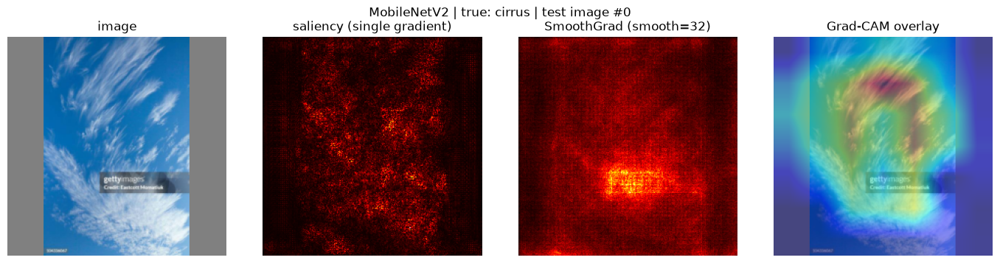

In [8]:
conf = PROBS[MAIN_KEY].max(axis=1)
correct_mask = PRED[MAIN_KEY] == y_test
demo_i = int(np.where(correct_mask)[0][0])
maps = get_maps(JOINED[MAIN_KEY], x_test[demo_i])
show_maps(x_test[demo_i], maps,
          f"{APPS[MAIN_KEY]['name']} | true: {class_names[y_test[demo_i]]} | test image #{demo_i}")
save_fig("n4_three_methods_demo"); plt.show()

**Comment on the difference between the single-gradient map and SmoothGrad:** *(write 2 to 3 sentences after looking at the picture. A single gradient is usually speckled and noisy. SmoothGrad averages gradients over 32 slightly noisy copies of the image, so it is smoother and the main regions stand out. Say what you see here.)*

### 1.4 Do the methods agree? A number, not just a picture
For `N_AGREE` test images we correlate the maps pixel by pixel (1 = identical pattern, 0 = unrelated). This feeds the discussion section.

In [9]:
def corr(a, b):
    return float(np.corrcoef(a.ravel(), b.ravel())[0, 1])

rng = np.random.default_rng(SEED)
agree_idx = rng.choice(len(x_test), size=min(N_AGREE, len(x_test)), replace=False)
rows = []
for i in agree_idx:
    m = get_maps(JOINED[MAIN_KEY], x_test[i])
    rows.append({"image": int(i),
                 "raw vs SmoothGrad":      corr(m["saliency"], m["smooth"]),
                 "SmoothGrad vs Grad-CAM": corr(m["smooth"],   m["gradcam"]),
                 "raw vs Grad-CAM":        corr(m["saliency"], m["gradcam"])})
agree_df = pd.DataFrame(rows).set_index("image")
display(agree_df.describe().loc[["mean", "min", "max"]].style.format("{:.2f}"))

,raw vs SmoothGrad,SmoothGrad vs Grad-CAM,raw vs Grad-CAM
mean,0.20,0.28,0.16
min,-0.06,-0.23,-0.14
max,0.42,0.77,0.44


## 2. Where to point them
The provided `xai.explain` plots the methods side by side for one image. We use it for every example below. The line above each plot is our own pipeline's prediction, so we can confirm the explainer is looking at the same model output we are.

**Check once:** the predicted class and confidence in each `xai.explain` title should match the line printed above it. If they do not, the explainer is applying different preprocessing from ours, and we must read `image_explainers.py` to see why.

### 2.1 Three correctly classified images (three different classes)

Correct examples: [(203, 'stratus'), (256, 'cumulonimbus'), (192, 'cumulus')]
[MobileNetV2] test image #203 | true: stratus | our prediction: stratus (0.99)


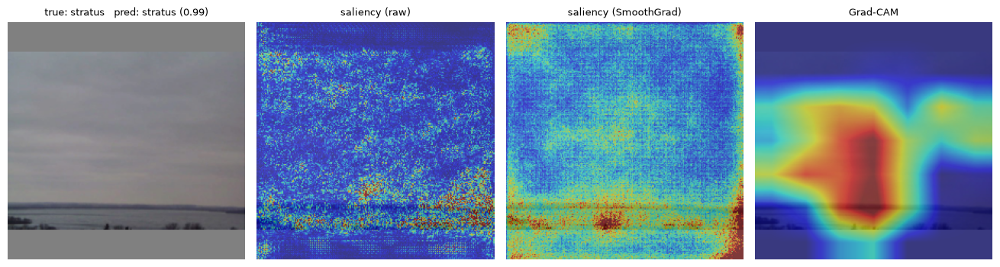

<Figure size 640x480 with 0 Axes>

[MobileNetV2] test image #256 | true: cumulonimbus | our prediction: cumulonimbus (1.00)


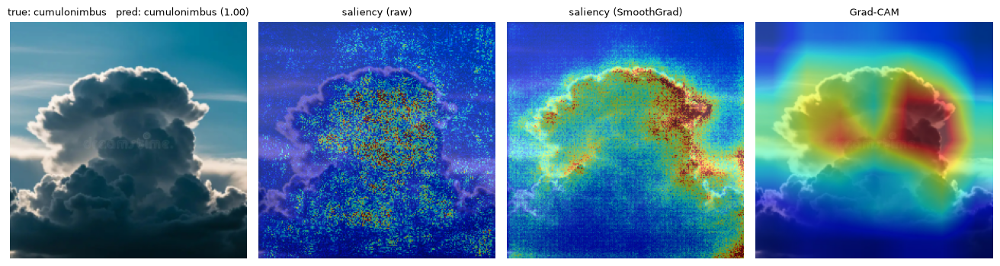

<Figure size 640x480 with 0 Axes>

[MobileNetV2] test image #192 | true: cumulus | our prediction: cumulus (1.00)


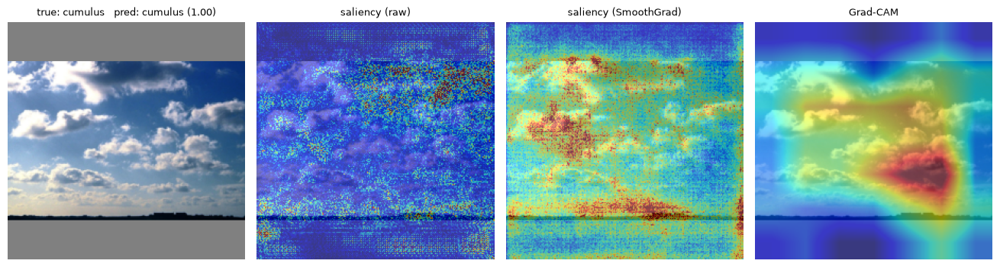

<Figure size 640x480 with 0 Axes>

In [10]:
rng = np.random.default_rng(SEED)
correct_idx = []
for c in rng.permutation(n_classes)[:N_CORRECT]:
    cand = np.where(correct_mask & (y_test == c))[0]
    if len(cand):
        correct_idx.append(int(cand[np.argmax(conf[cand])]))     # most confident correct image of that class
print("Correct examples:", [(i, class_names[y_test[i]]) for i in correct_idx])
for i in correct_idx:
    explain_one(MAIN_KEY, i)

**What the model looks at when it is right:** *(for each of the three images say whether the hot region sits on the cloud, the sky, the horizon, or something else.)*

### 2.2 Three misclassified images
These are the informative ones. We take the model's **most confident mistakes** (one per true class where possible), because a confident wrong answer shows what it was sure about.

Misclassified examples: [(196, 'cumulus', '->', 'cumulonimbus'), (41, 'stratus', '->', 'altocumulus'), (269, 'cumulonimbus', '->', 'cumulus')]
[MobileNetV2] test image #196 | true: cumulus | our prediction: cumulonimbus (1.00)


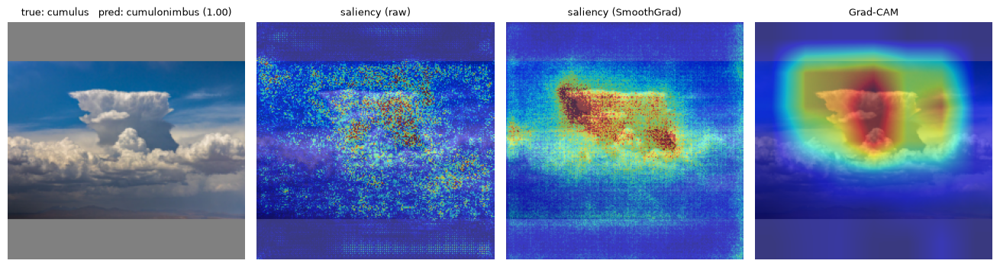

<Figure size 640x480 with 0 Axes>

[MobileNetV2] test image #41 | true: stratus | our prediction: altocumulus (1.00)


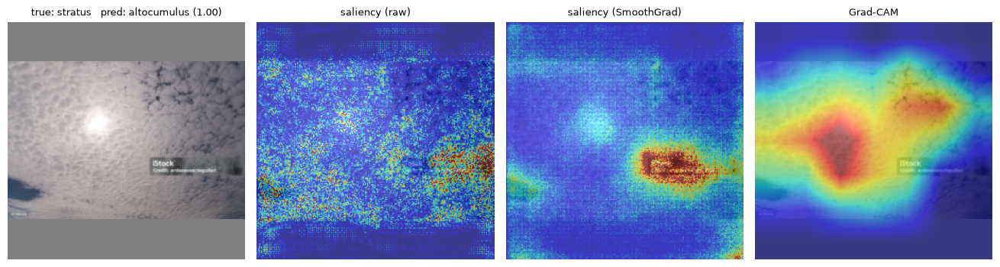

<Figure size 640x480 with 0 Axes>

[MobileNetV2] test image #269 | true: cumulonimbus | our prediction: cumulus (0.99)


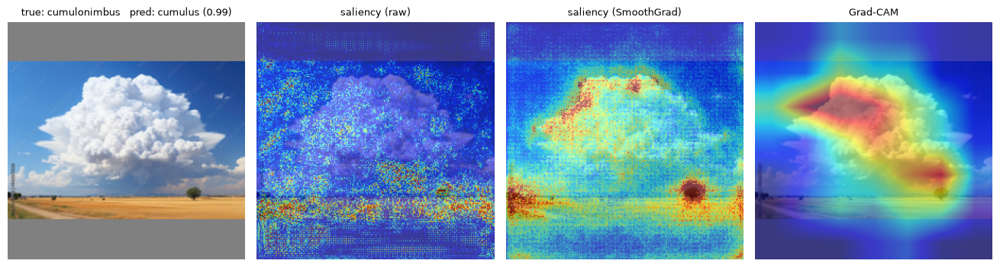

<Figure size 640x480 with 0 Axes>

In [11]:
wrong = np.where(~correct_mask)[0]
wrong = wrong[np.argsort(-conf[wrong])]                           # most confident mistakes first
wrong_idx, seen = [], set()
for i in wrong:
    if y_test[i] not in seen:
        wrong_idx.append(int(i)); seen.add(y_test[i])
    if len(wrong_idx) == N_WRONG:
        break
for i in wrong:                                                   # top up if fewer classes than N_WRONG
    if len(wrong_idx) >= N_WRONG: break
    if int(i) not in wrong_idx: wrong_idx.append(int(i))
print("Misclassified examples:", [(i, class_names[y_test[i]], "->", class_names[PRED[MAIN_KEY][i]]) for i in wrong_idx])
for i in wrong_idx:
    explain_one(MAIN_KEY, i)

**What was the model looking at when it was wrong?** *(for each image: the wrong object, the background, a watermark or banner, or something you cannot identify? Also say whether the photo itself might be mislabeled. Several stratus samples in Notebook 2 looked like other cloud types.)*

### 2.3 The same image across all applications, side by side
Does the larger application *localize the subject better*, or does it just score higher? We compare one image where the applications disagree and one where they all agree.

Comparing images: [1, 0] (first: applications disagree; second: all correct)


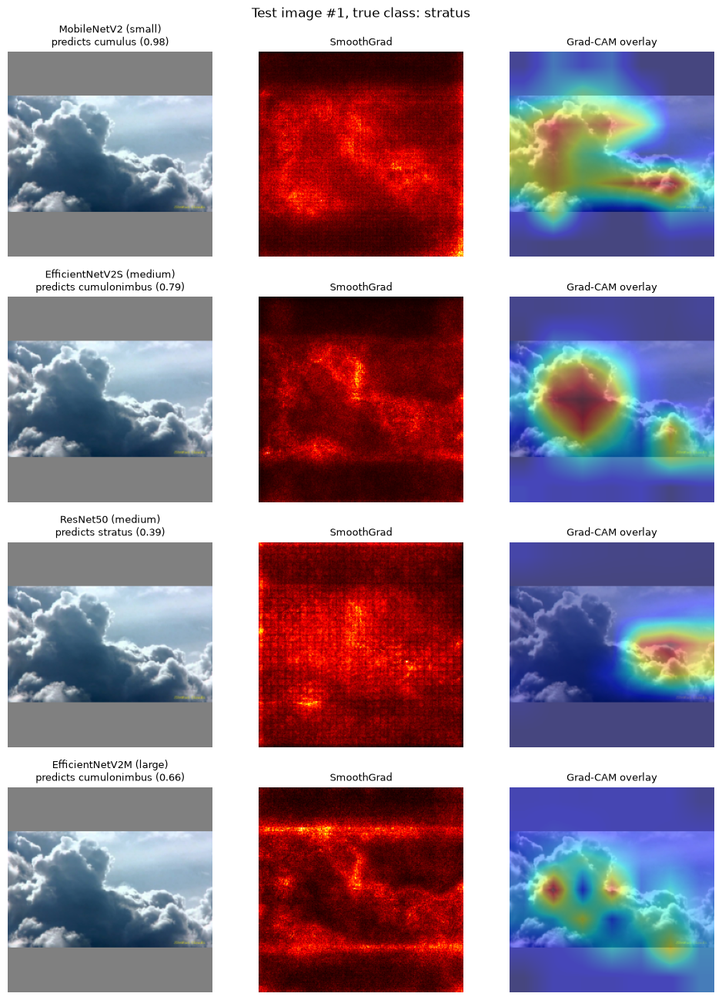

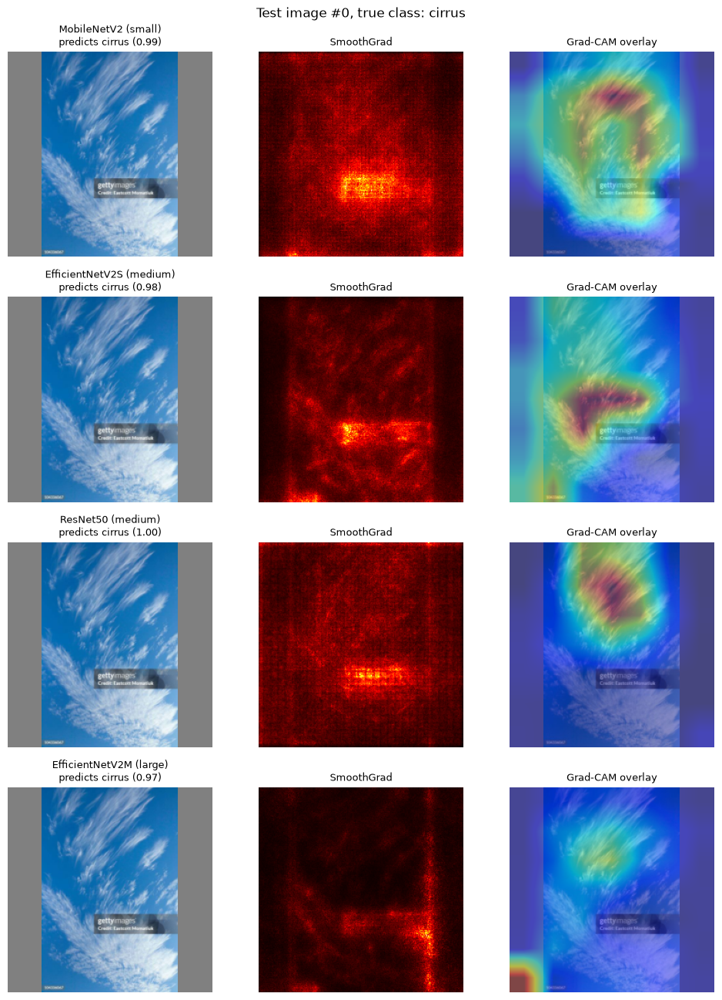

In [12]:
def compare_apps(i, keys=None):
    keys = keys or AVAILABLE
    fig, axes = plt.subplots(len(keys), 3, figsize=(10, 3.3 * len(keys)))
    axes = np.atleast_2d(axes)
    for r, k in enumerate(keys):
        m = get_maps(JOINED[k], x_test[i])
        p = PROBS[k][i]
        axes[r, 0].imshow(x_test[i])
        axes[r, 0].set_title(f"{APPS[k]['name']} ({APPS[k]['size']})\npredicts {class_names[p.argmax()]} ({p.max():.2f})", fontsize=9)
        axes[r, 1].imshow(m["smooth"], cmap="hot");    axes[r, 1].set_title("SmoothGrad", fontsize=9)
        axes[r, 2].imshow(overlay(x_test[i], m["gradcam"])); axes[r, 2].set_title("Grad-CAM overlay", fontsize=9)
        for ax in axes[r]: ax.axis("off")
    fig.suptitle(f"Test image #{i}, true class: {class_names[y_test[i]]}")
    plt.tight_layout(); save_fig(f"n4_compare_apps_{i}"); plt.show()

ok_by_app = np.array([PRED[k] == y_test for k in AVAILABLE])
disagree = np.where(~ok_by_app.all(axis=0) & ok_by_app.any(axis=0))[0]     # some right, some wrong
all_right = np.where(ok_by_app.all(axis=0))[0]
compare_idx = [int(a[0]) for a in (disagree, all_right) if len(a)]
print("Comparing images:", compare_idx, "(first: applications disagree; second: all correct)")
for i in compare_idx:
    compare_apps(i)

**Does the large application localize better or just score higher?** *(compare how tightly each Grad-CAM sits on the cloud across rows. Use the accuracy table in section 0.3 as well.)*

## 3. Shortcut hunt
Scraped photos carry clues that are not clouds. From Notebook 2 we already know about three candidates:

1. **Stock-photo watermarks and banners.** The per-class mean images for altocumulus, cirrus and cumulus showed a faint repeated "alamy" watermark and a dark banner near the bottom of the photo. Shutterstock and Deposit Photos captions and overlays also showed up in the sample grid, unevenly across classes.
2. **Letterbox bars.** Notebook 2 pads photos to 224 x 224 with flat gray bars. The bar size depends on the photo's shape, and the shape could correlate with class.
3. **Background and framing** that depends on how we searched (for example, stratus photos shot from planes).

### 3.1 Do the maps land on the structure in the mean images?
Top row: the per-class mean training image (from Notebook 2). Bottom row: the **average Grad-CAM** of the test images of that class. If the hot area of the bottom row matches the banner or bars of the top row, that is evidence the model uses them.

Grad-CAM computed for 120 test images in 65s


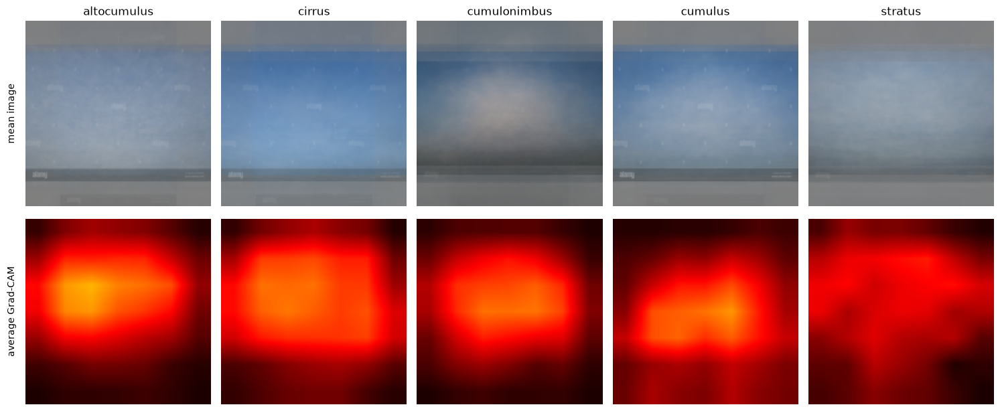

In [13]:
x_train = np.load(OUT_DIR / "x_train.npy")
y_train = np.load(OUT_DIR / "y_train.npy")
if y_train.ndim > 1: y_train = y_train.argmax(axis=1)

def content_box(img, tol=2.0):
    """(top, bottom) rows of the real photo: trims flat letterbox bars added in Notebook 2."""
    flat = img.astype("float32").std(axis=1).mean(axis=1) < tol      # one flag per row
    top = 0
    while top < len(flat) and flat[top]:
        top += 1
    if top == len(flat):
        return 0, len(flat)
    bot = len(flat)
    while flat[bot - 1]:
        bot -= 1
    return top, bot

def region_masks(img):
    """Boolean masks (224 x 224) for the bottom banner strip and for the flat bars."""
    top, bot = content_box(img)
    h = max(1, int(BANNER_FRAC * (bot - top)))
    banner = np.zeros((IMG_SIZE, IMG_SIZE), bool); banner[bot - h:bot] = True
    bars   = np.zeros((IMG_SIZE, IMG_SIZE), bool); bars[:top] = True; bars[bot:] = True
    return banner, bars

def attention_shares(key, idx):
    """For each image: how much of the Grad-CAM heat falls on the banner strip and on the bars."""
    rows, cams = [], []
    for i in idx:
        cam = to_map(xai.grad_cam(JOINED[key], x_test[i]))
        banner, bars = region_masks(x_test[i])
        tot = cam.sum() + 1e-8
        rows.append({"image": int(i), "true": class_names[y_test[i]],
                     "banner_mass": cam[banner].sum() / tot, "banner_area": banner.mean(),
                     "bars_mass":   cam[bars].sum() / tot,   "bars_area":   bars.mean()})
        cams.append(cam)
    df = pd.DataFrame(rows)
    df["banner_ratio"] = df.banner_mass / df.banner_area
    df["bars_ratio"]   = df.bars_mass / df.bars_area.replace(0, np.nan)
    return df, np.stack(cams)

rng = np.random.default_rng(SEED)
attn_idx = np.sort(rng.choice(len(x_test), size=min(N_ATTN, len(x_test)), replace=False))
t0 = time.time()
attn_df, attn_cams = attention_shares(MAIN_KEY, attn_idx)
print(f"Grad-CAM computed for {len(attn_idx)} test images in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, n_classes, figsize=(3 * n_classes, 6.4))
for c in range(n_classes):
    axes[0, c].imshow(x_train[y_train == c].astype("float32").mean(axis=0).astype("uint8"))
    axes[0, c].set_title(class_names[c]); axes[0, c].axis("off")
    sel = np.array([class_names[y_test[i]] == class_names[c] for i in attn_idx])
    if sel.any():
        axes[1, c].imshow(attn_cams[sel].mean(axis=0), cmap="hot", vmin=0, vmax=1)
    axes[1, c].axis("off")
axes[0, 0].text(-0.05, 0.5, "mean image", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.05, 0.5, "average Grad-CAM", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); save_fig("n4_mean_image_vs_gradcam"); plt.show()

**What the comparison shows:** *(describe whether the bright areas of the average Grad-CAM line up with the banner or bars in the mean images, class by class.)*

### 3.2 Attention ratio: how much heat falls on the banner strip and on the bars?
A **ratio of 1.0** means the model gives the region exactly as much attention as its share of the image. A ratio well above 1 means it over-attends to that region. The banner is the bottom 12% of the real photo, and the bars are the flat padding.

In [14]:
summary_attn = attn_df.groupby("true")[["banner_ratio", "bars_ratio"]].mean()
summary_attn.loc["ALL"] = attn_df[["banner_ratio", "bars_ratio"]].mean()
display(summary_attn.style.format("{:.2f}"))
print(f"Images with letterbox bars: {int((attn_df.bars_area > 0).sum())} of {len(attn_df)}")

,banner_ratio,bars_ratio
true,,
altocumulus,0.33,0.32
cirrus,0.56,0.50
cumulonimbus,0.55,0.36
cumulus,0.83,0.50
stratus,0.60,0.66
ALL,0.54,0.45


Images with letterbox bars: 93 of 120


**Reading the table:** *(a banner ratio above about 1.5 for a class suggests over-attention to the strip. Say which classes, if any. This is a hint; the ablation below is the measurement.)*

### 3.3 Which test images carry a watermark? (manual tagging)
No code can reliably spot every watermark, so we look. Page through the test set below, note the numbers of images with a visible watermark, logo, caption strip or text overlay, and fill in `WATERMARKED`. This lets us check whether watermarks are spread evenly across classes and whether accuracy differs on them.

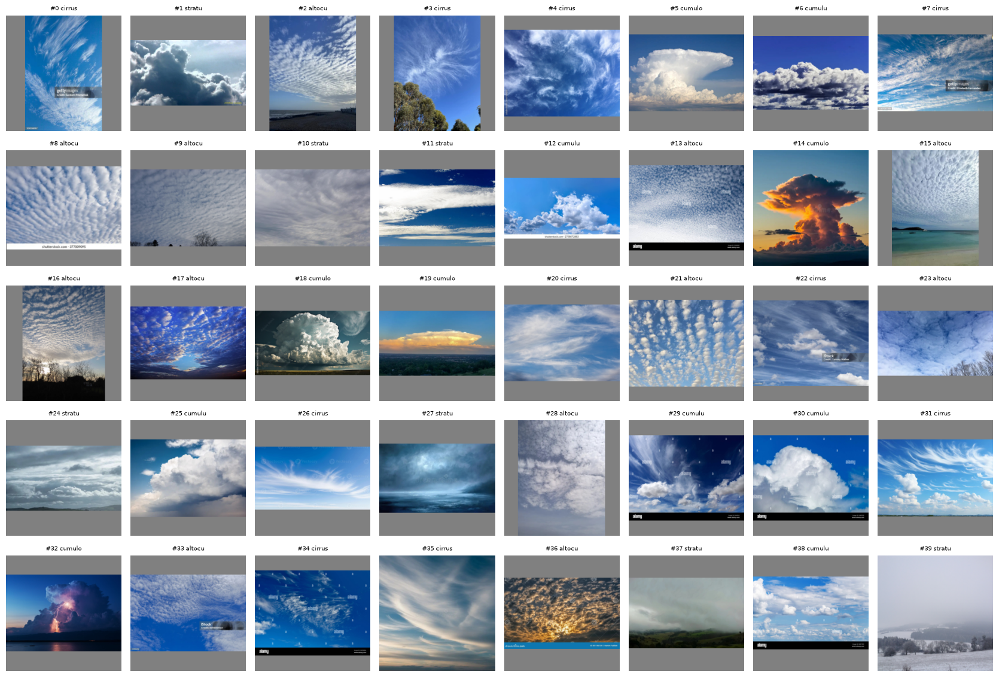

In [15]:
def contact_sheet(start=0, n=40, cols=8):
    idx = list(range(start, min(start + n, len(x_test))))
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.3 * rows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(x_test[i]); ax.set_title(f"#{i} {class_names[y_test[i]][:6]}", fontsize=7)
    plt.tight_layout(); plt.show()

contact_sheet(0)        # then 40, 80, 120 ... up to len(x_test)

In [16]:
WATERMARKED = []        # <- type the image numbers you tagged, for example [3, 17, 18, 52]

if WATERMARKED:
    wm = np.zeros(len(x_test), bool); wm[WATERMARKED] = True
    display(pd.crosstab(pd.Series([class_names[c] for c in y_test], name="class"),
                        pd.Series(wm, name="watermarked")))
    rows = []
    for k in AVAILABLE:
        ok = PRED[k] == y_test
        rows.append({"application": APPS[k]["name"],
                     "accuracy, watermarked": ok[wm].mean(), "accuracy, clean": ok[~wm].mean(),
                     "n watermarked": int(wm.sum())})
    display(pd.DataFrame(rows).style.format({"accuracy, watermarked": "{:.3f}", "accuracy, clean": "{:.3f}"}))
else:
    print("WATERMARKED is empty. Fill it in after paging through the contact sheets above.")

WATERMARKED is empty. Fill it in after paging through the contact sheets above.


**Are watermarks spread evenly across classes?** *(use the table. If one class is far more watermarked than the others, a model can learn the watermark as a class clue.)*

### 3.4 Ablation: blank out the suspect region and re-measure accuracy
A picture suggests; an ablation measures. We re-score the **whole test set** with:

| Variant | What we blank out | What it tests |
|---|---|---|
| **banner** | the bottom 12% of the real photo, painted mid-gray | reliance on watermarks, banners and caption strips |
| **control** | a band of the **same size** at a random place in the photo | the damage from simply hiding *some* pixels. This is the fair comparison. |
| **bars_black** | the letterbox padding, recolored black | reliance on the padding / photo shape |

If the banner variant hurts accuracy **much more than the control**, the model was using the banner. We also give a 95% bootstrap interval for the banner drop, because with a test set this small a change of a couple of points is within noise.

270 of 321 test images have letterbox bars


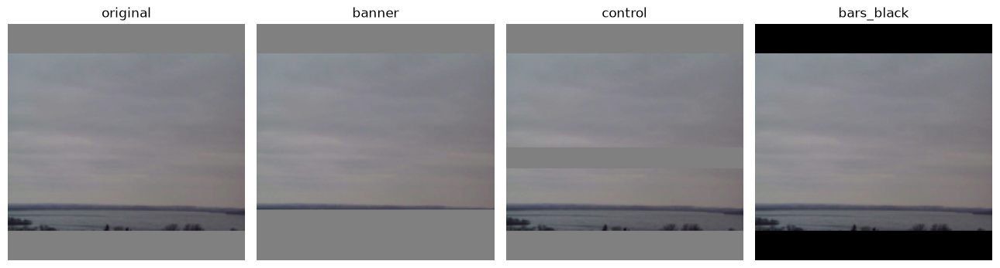

In [17]:
def ablate(x, kind, seed=SEED):
    rng = np.random.default_rng(seed)
    out = x.copy()
    for i, img in enumerate(x):
        top, bot = content_box(img)
        h = max(1, int(BANNER_FRAC * (bot - top)))
        if kind == "banner":
            out[i, bot - h:bot] = GREY
        elif kind == "control":
            start = int(rng.integers(top, max(top + 1, bot - 2 * h)))   # never overlaps the banner strip
            out[i, start:start + h] = GREY
        elif kind == "bars_black":
            out[i, :top] = 0; out[i, bot:] = 0
    return out

def boot_ci(ok_a, ok_b, n_boot=2000, seed=0):
    """95% bootstrap interval for the drop in accuracy (points) from ok_a to ok_b, same images."""
    rng = np.random.default_rng(seed)
    n = len(ok_a); d = []
    for _ in range(n_boot):
        s = rng.integers(0, n, n)
        d.append((ok_a[s].mean() - ok_b[s].mean()) * 100)
    return np.percentile(d, [2.5, 97.5])

KINDS = ("banner", "control", "bars_black")
x_variants = {k: ablate(x_test, k) for k in KINDS}
n_bars = sum(content_box(img) != (0, IMG_SIZE) for img in x_test)
print(f"{n_bars} of {len(x_test)} test images have letterbox bars")

# One quick look at what we are blanking out
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
show_i = int(correct_idx[0]) if correct_idx else 0
for ax, (lab, im) in zip(axes, [("original", x_test[show_i])] + [(k, x_variants[k][show_i]) for k in KINDS]):
    ax.imshow(im); ax.set_title(lab); ax.axis("off")
plt.tight_layout(); save_fig("n4_ablation_examples"); plt.show()

In [18]:
rows = []
for key in AVAILABLE:
    base_ok = PRED[key] == y_test
    row = {"application": APPS[key]["name"], "base accuracy %": base_ok.mean() * 100}
    for kind in KINDS:
        pv = predict_proba(key, x_variants[kind]).argmax(axis=1)
        ok = pv == y_test
        row[f"{kind} drop (pts)"]  = (base_ok.mean() - ok.mean()) * 100
        row[f"{kind} flipped"]     = int((pv != PRED[key]).sum())
        if kind == "banner":
            lo, hi = boot_ci(base_ok, ok)
            row["banner drop 95% CI"] = f"[{lo:+.1f}, {hi:+.1f}]"
    rows.append(row)
ablation_df = pd.DataFrame(rows)
display(ablation_df.style.format({c: "{:.1f}" for c in ablation_df.columns
                                  if c.endswith("(pts)") or c == "base accuracy %"}))

,application,base accuracy %,banner drop (pts),banner flipped,banner drop 95% CI,control drop (pts),control flipped,bars_black drop (pts),bars_black flipped
0,MobileNetV2,73.2,-1.9,48,"[-5.6, +1.9]",2.5,60,2.5,49
1,EfficientNetV2S,80.1,0.9,36,"[-2.2, +4.1]",3.7,21,1.9,29
2,ResNet50,78.2,-1.6,27,"[-4.7, +1.2]",6.2,67,1.9,33
3,EfficientNetV2M,71.0,1.2,57,"[-2.5, +5.3]",-1.2,42,2.5,44


**How to read the ablation table**
- **drop (pts):** accuracy before minus accuracy after, in percentage points. Positive means the model got worse.
- **flipped:** how many test images changed prediction.
- **Verdict rule we use:** a shortcut is *supported* only if the banner drop is clearly larger than the control drop **and** its 95% interval stays above zero. A drop similar to the control just means hiding pixels hurts a little.

**Our shortcut verdict:** *(write one of: "We found a shortcut: ..." with the numbers, or "We found no shortcut: ..." with the evidence. A clean result honestly shown earns full marks.)*

### 3.5 Does the answer hold for every application?
Compare the banner and control drops across the rows of the table above. A shortcut that hurts the small application but not the large one is itself a finding.

## 4. Discussion

*TeamKAI: write these after the cells above have run, using the numbers printed above.*

**Do the two methods agree?**  
Use the correlation table in section 1.4. Say how similar raw saliency, SmoothGrad and Grad-CAM are on average. Then name one image from sections 2.1 to 2.3 where they point to different places and say what that disagreement tells you: gradient maps can light up on edges and texture the model reacts to, while Grad-CAM shows regions the last layer used. Disagreement is a diagnosis, not a failure.

**Would we deploy this model?**  
Answer yes or no and rest it on three things we measured: test accuracy, the weakest class's recall from Notebook 3, and the ablation result. Then name the **first** thing we would fix and why. Choose from more data (stratus has the fewest distinct photos), better cleaning (remaining duplicates, text pages, mislabeled stratus), removing or cropping watermark banners, different classes, or a different Keras application.

**What would change our mind?**  
Name one result that would reverse your decision, for example a banner drop much larger than the control, or a class whose recall collapses on watermark-free images.